# KQC Demo — four coupled Swissmons, two probe lines, charge and flux lines (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' demonstration chip (`chips/demo.py`, class `Demo`; © IQM Finland Oy, GPL-3.0,
<https://github.com/iqm-finland/KQCircuits>; local copy `other-libs/KQCircuits-main/.../kqcircuits/chips/demo.py`).
Four Swissmon qubits sit at the corners of a 3560 × 4000 µm rectangle and are coupled in a ring by four CPW
couplers between their side couplers. Each qubit has a λ/2 readout resonator ending on a finger capacitor on a T
in a probe line (two probe lines, two qubits each, each with a tapered finger capacitor at its input), a charge
line and a flux line, all from an ARD24 sample holder. Two junction-test arrays sit at the sides.

This notebook **rebuilds** that chip with our components, routes, netlist and LOM on the Quantcore PDK — it is
not a replica. We distribute the rebuild under GPL-3.0. The table says what is kept and what the PDK changes.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` (dicing edge, IQM markers, labels) | same 10 × 10 mm (the ARD24 launchers sit on its edges; it does not fit the 7.5 mm die), Quantcore die frame: L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "Demo" |
| launchers | ARD24, `launcher_indent` 680 µm (outer etch 21 µm from the edge) | ARD24, indent **759 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm from the edge, 79 µm further in than KQC's); same pad assignment |
| substrate | KQC simulation default silicon, εr 11.45 | sapphire 650 µm, εr 10.25 |
| junctions | KQC Manhattan SQUIDs (assumed L_J 16 nH) | Quantcore Nb/AlOx/Nb trilayer SQUIDs, 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH |
| cheese | KQC's whole-area ground grid (`with_grid`, 5 µm holes on a 10 µm step, in KQC's mask builds) | the same whole-area coverage with the PDK squares: chip `cheese: "chip"` puts 5 µm squares with 20 µm gaps (instead of KQC's 5 µm on a 10 µm step) over the whole die, at least 4 µm from the 3/0 keep-outs and clear of the frame markers and the device ID |
| elements, positions, routes | — | kept: every KQC element with the source's parameters, positions and orientations; waypoints derived from the launcher ports |
| placement | centred | centred (checked below, no shift) |

**Simplified:** each readout's meander is one KQC `Meander` the router fits to the leftover length on the 1100 µm segment, instead of KQC's `Meander` of fixed width; the couplers' and probe lines' extra airbridges (`n_bridges`) are left out. The readouts end on a
capacitor at both ends, so they are λ/2 (≈ 11 GHz for 5000 µm on sapphire), as in the source.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die with its ARD24 launchers, the launchers and the pad rule, the four qubits (first: the readout parts are placed from their ports), the two probe lines with the readout capacitors and T's, the four λ/2 readouts, the ring couplers, the charge and flux lines, and then the whole chip (the sim groups, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `demo.v1.ipynb`; both save the same `demo.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/demo/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")               # design JSON + final snapshots
STEPS = Path("build/snapshots/demo")             # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the SQUIDs, and the
cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | 5 µm squares, 20 µm gaps, ≥ 4 µm from the 3/0 keep-outs: a band of 3 rows around them, or the whole die (`cheese: "chip"`); an original design's own rule or holes where it has them (chip param `cheese`: auto / pdk / chip / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die and its launchers, the qubits, the readout line,
the readout resonators, the coupling, the control lines, and then the whole chip. Each segment is one cell with one
picture of the chip so far (live, KLayout redraws after every cell).

**Why the qubits come before the readout line here.** KQC places each readout capacitor and its probe-line T along
the readout path out of the qubit's coupler 1 (`shift_away(xy(QB.cplr1), …)`: 600 µm out, 300 µm sideways, 1100 µm
further), so they follow the qubit, and the probe lines run through those T's. The order is the geometry's: the
calls keep the v1's order, nothing is recomputed to put the line first. The PDK cheese (`cheese: "chip"`, ≈ 0.12 M holes over the whole die) is drawn in every build, so each picture rebuilds the whole chip:
the pictures stay at the v1's size, one per segment.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame and KQC's ARD24 launcher assignment (twelve launchers) |
| 2 | the launchers and the pad rule (they come with the die: a look and a table) |
| 3 | the qubits: four Swissmons with their trilayer SQUIDs, and the two junction-test arrays |
| 4 | the readout line: per qubit a readout capacitor and its probe-line T, the two input capacitors, the two probe lines |
| 5 | the readout resonators: four λ/2 lines, coupler 1 → capacitor |
| 6 | the coupling: four ring couplers between the qubits' side couplers |
| 7 | the control routing: four charge lines and four flux lines |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die, its frame and the launchers

`Designer(...)` starts the chip: the 10 × 10 mm box, the ARD24 sample-holder launchers with KQC's assignment for
the Demo chip (pad numbers clockwise from the top-left; only the assigned ones are drawn) and the chip name
"Demo", which the Quantcore frame writes as the device ID on a free edge. `cheese: "chip"` asks for the PDK cheese over the whole die: KQC's source grids its whole ground plane (`with_grid=True`, 5 µm holes on a 10 µm step), and the rebuild keeps that coverage with the PDK squares (5 µm with 20 µm gaps, at least 4 µm from the 3/0 keep-outs).

The frame itself is the PDK default: L dicing markers on 1000/0 at the corners, 3 × 3 alignment grids on 1001/0
and the chip boundary on 100/0. KQC's own `ChipFrame` is not drawn.

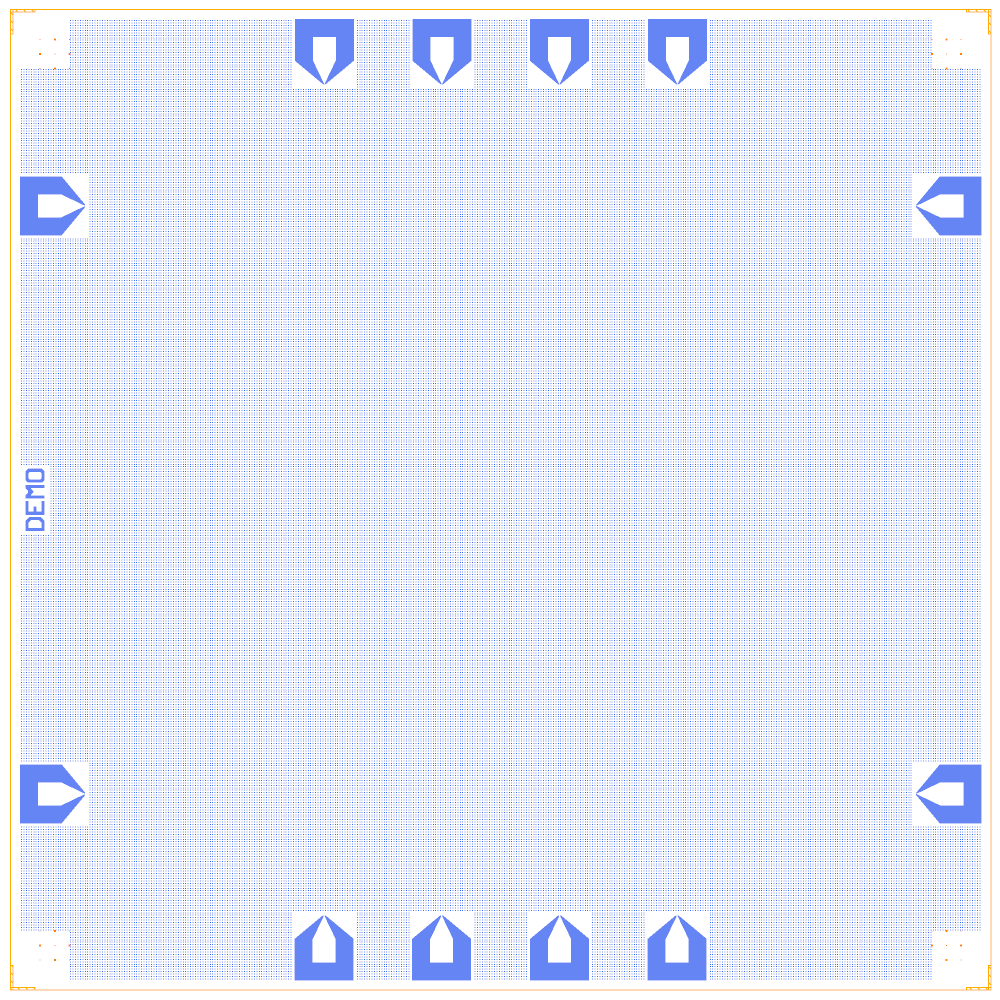

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout. The ARD24 launchers belong to the chip (the sample holder), not to the instances, so the pad count stays 0.

WindowsPath('build/snapshots/demo/1_die.png')

In [5]:
# KQC launcher assignment of the Demo chip (ARD24 pad numbers, clockwise from the top-left); only these are drawn
pads = {2: "FL-QB1", 3: "PL-1-IN", 4: "PL-1-OUT", 5: "FL-QB2", 7: "DL-QB2", 12: "DL-QB4", 14: "FL-QB4",
        15: "PL-2-IN", 16: "PL-2-OUT", 17: "FL-QB3", 19: "DL-QB3", 24: "DL-QB1"}
d = Designer("demo", box=(0, 0, 10000, 10000), launchers={"type": "ARD24", "assign": pads},
             chip={"name_chip": "Demo", "cheese": "chip"}, live=LIVE)
L = {name: f"chip.{name}" for name in pads.values()}       # launcher ports, referenced as "chip.<name>"
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "1_die.png", **CHIP,
            note="The ARD24 launchers belong to the chip (the sample holder), not to the instances, so the"
                 " pad count stays 0.")

## Design 2 · Bond pads: the launchers and the pad rule

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge.
For KQC sample-holder launchers the Designer applies it by computing `launcher_indent` (die edge → launcher
port): RF launcher = 100 µm + taper (240 µm) + pad (240 µm) + gap (179 µm) = **759 µm** (KQC: 680 µm, i.e. the
outer edge 21 µm from the edge). Every route (Designs 4 and 7) starts from these ports, so nothing else moves with the
rule. (Stand-alone pads, e.g. a `BondPad`, take `edge="auto"` in `d.add` instead; this chip has none.)

The launchers came with the die (Design 1): nothing is added here. The table measures them, the picture zooms on PL-1-IN.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.FL-QB1 | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-1-IN | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-1-OUT | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.FL-QB2 | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB2 | launcher port | e | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB4 | launcher port | e | port 759 µm in (indent from the rule) | ✓ |
| chip.FL-QB4 | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-2-IN | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-2-OUT | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.FL-QB3 | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB3 | launcher port | w | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB1 | launcher port | w | port 759 µm in (indent from the rule) | ✓ |

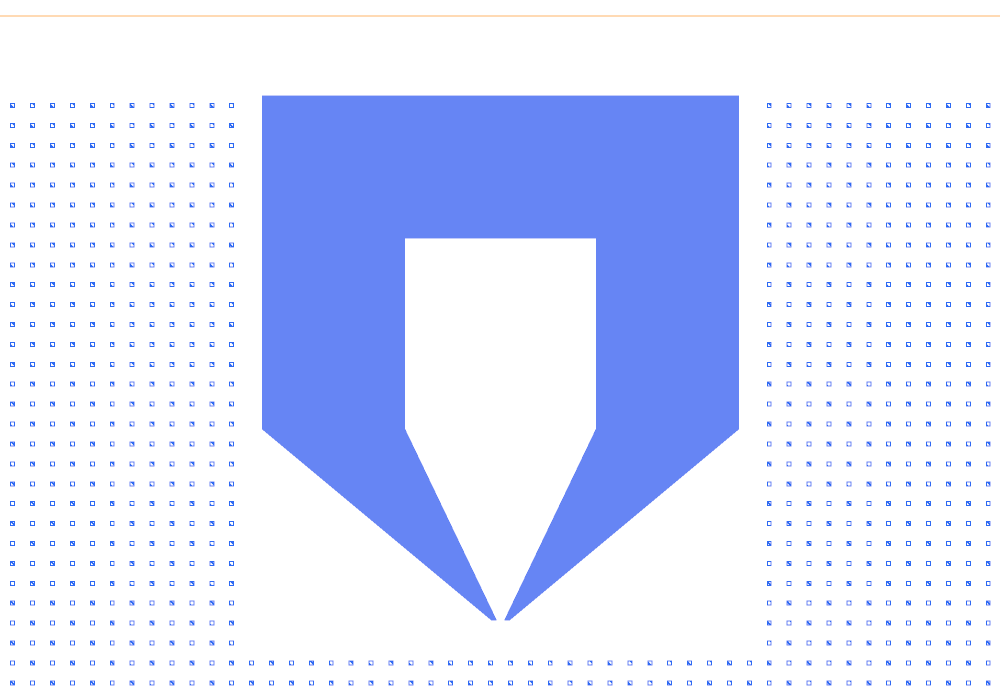

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, L["PL-1-IN"])
snap(d, STEPS / "2_launcher.png", box=(x - 400, y - 100, x + 400, 10000 + 20), size=(1000, 700), width=420);

## Design 3 · Qubit placement: four Swissmons (before the readout line)

**Qubits.** Four KQC `Swissmon`s at KQC's positions, mirrored / rotated as KQC's `DTrans(0, True, …)`,
`DTrans(2, False, …)`, …: three couplers of 120 µm (`cpl_length`), port widths 4/10/4 µm, the standard flux line.
Ports: `cplr0`–`cplr2` (couplers), `drive` (charge line), `flux`. The SQUID at the top arm carries the trilayer
junction parameters of the junction cell below.

The helpers: `port_xy(d, ref)` is the absolute position of a port, `corner(ref)` is KQC's `"<port>_corner"`
refpoint (one turn radius out along the port), `shift_away(p, base, dist)` moves a point further from a centre.

**The junction from the PDK rule.** KQC draws a SQUID in every Swissmon. `trilayer_junction` turns it into the
Quantcore trilayer SQUID: two junctions whose straight finger is KQC's `junction_width` (the bent finger stays at
the PDK 0.6 µm). With the nominal L_J (6.73 nH, the 0.5 × 0.6 µm junction at R_n 45 kΩ) as the SQUID's parallel
total, each junction is 0.25 × 0.6 µm. `JJ_PARAMS` go on the cell, `JUNCTION` (L_J, C_J) is what the LOM and the
FEM junction ports use.

**Junction-test arrays.** KQC's `JunctionTestPads` at both sides, with the same trilayer SQUID.

The first picture is the chip so far, the second zooms on QB1 (no rebuild: the same build).

In [7]:
LJ_PDK = trilayer_junction("Swissmon")[1]["Lj_nH"]          # PDK nominal L_J (0.5 × 0.6 µm junction, R_n 45 kΩ)
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon", lj_nH=LJ_PDK, squid=True)
print("cell parameters:", JJ_PARAMS)
print("LOM junction:   ", JUNCTION)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_width': 0.25}
LOM junction:    {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


<Swissmon QB1 ports=['cplr0', 'cplr1', 'cplr2', 'drive', 'flux']>


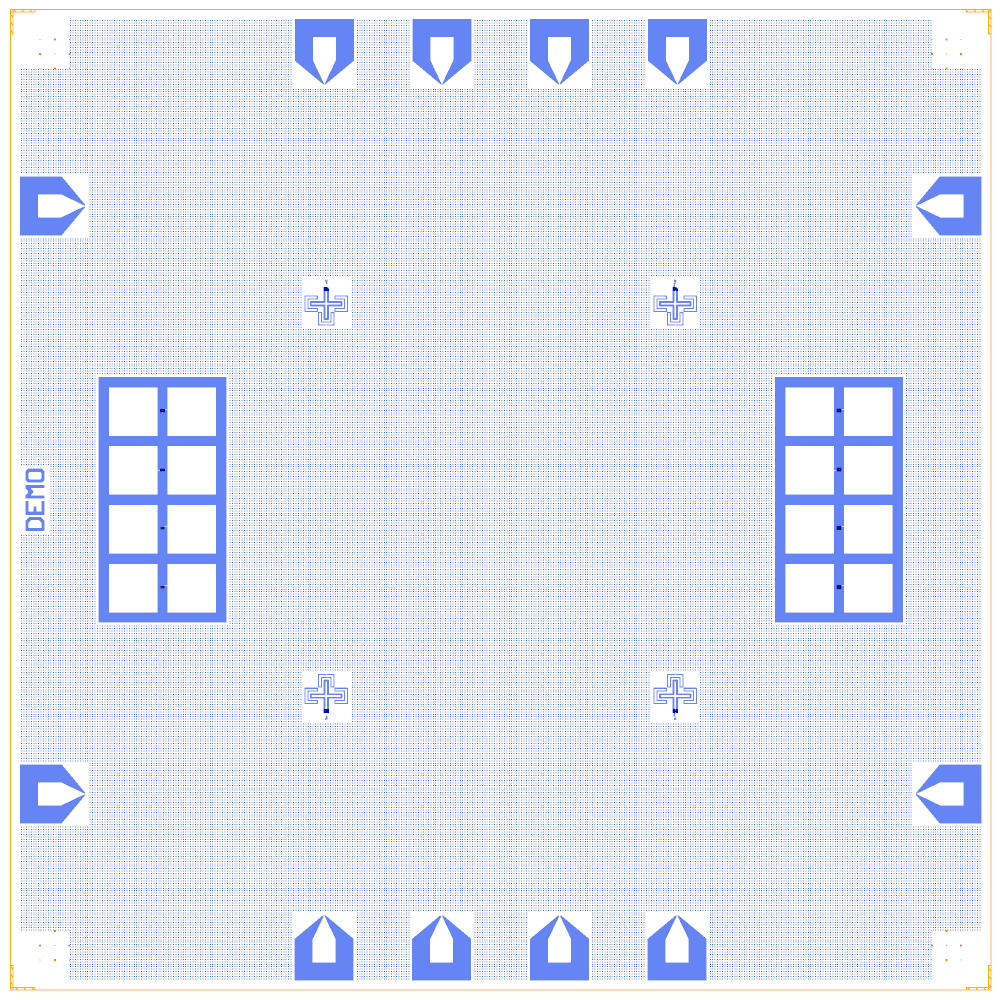

**On the chip so far:** 0 pads · 0 qubits · 6 other components · 0 routes · 0 declared couplings. **This step added** 6 component(s) `QB1`, `QB2`, `QB3`, `QB4`, `JT_W`, `JT_E`. KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among the other components.

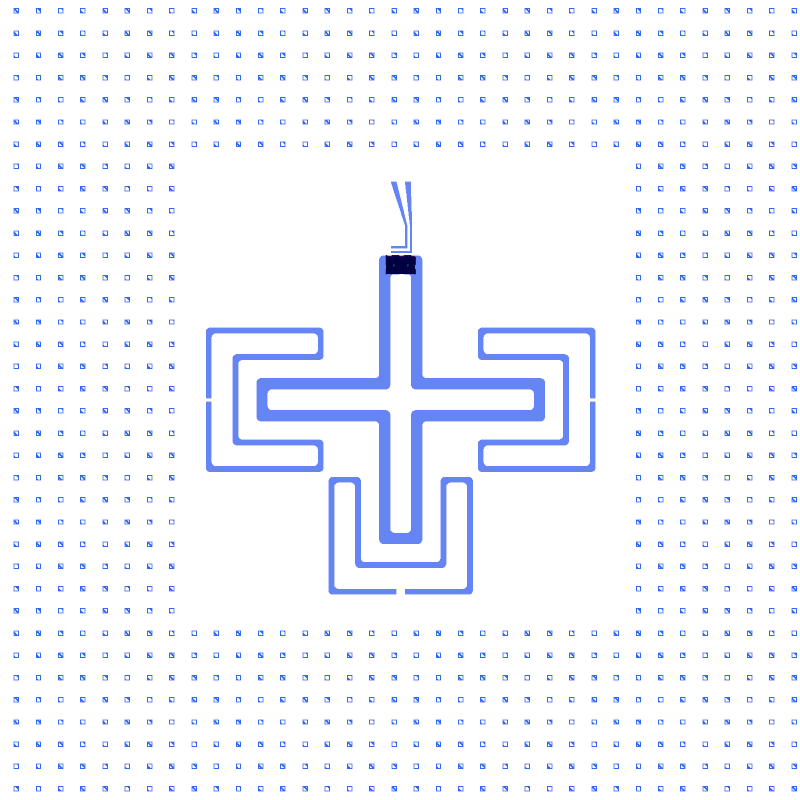

In [8]:
def xy(ref):                                     # absolute port position
    return port_xy(d, ref)


def corner(ref, dist=100.0):                     # KQC "<port>_corner": one turn radius out along the port
    x, y, a = port_info(d, ref)
    return (x + dist * math.cos(math.radians(a)), y + dist * math.sin(math.radians(a)))


# qubits: (x, y, rotation, mirror) as KQC's DTrans(0, True, …), DTrans(2, False, …), …
base = {"QB1": (3220, 7000, 0, True), "QB2": (6780, 7000, 180, False),
        "QB3": (3220, 3000, 0, False), "QB4": (6780, 3000, 180, True)}
with d.batch():
    qb = {n: d.add(n, "Swissmon", at=(x, y), rot=r, mirror=m, cpl_length=[120, 120, 120], port_width=[4, 10, 4],
                   junction=JUNCTION, **JJ_PARAMS) for n, (x, y, r, m) in base.items()}
print(qb["QB1"])
with d.batch():                                  # the junction-test arrays: the same trilayer SQUID
    JTP = "kqcircuits.test_structures.junction_test_pads.junction_test_pads.JunctionTestPads"
    for name, x in (("JT_W", 900), ("JT_E", 7800)):
        d.add(name, JTP, at=(x, 3750), margin=50, area_height=2500, **JJ_PARAMS)
layout_step(d, STEPS / "s3_qubits.png", **CHIP,
            note="KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among "
                 "the other components.")
qx, qy = base["QB1"][:2]
snap(d, STEPS / "s3_qb1.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(800, 800), width=320);

## Design 4 · Readout: the readout capacitors, the T's and the two probe lines

**Readout capacitors and probe-line T's.** Each readout resonator ends on a `FingerCapacitorSquare` (4, 8, 5 and
7 fingers) placed 600 µm out of the qubit's coupler 1, 300 µm sideways and 1100 µm further (KQC's readout path).
A `WaveguideCoplanarSplitter` T is snapped to the capacitor's far port: the probe line runs through its
`left`/`right` arms. Each probe line starts with a `FingerCapacitorTaper` (6 / 3 fingers, 20 µm taper) 2000 µm
from its first T. `add_aligned` places a cell by one of its ports (KQC's `insert_cell(..., align=port)`).

**Probe lines.** Input launcher → tapered capacitor → T of qubit a → T of qubit b → output launcher; the first and
last legs start at the launcher's corner, turn along the T's x, and cross the ring coupler on an airbridge at the
qubits' y.

Routes join two ports with CPW (PDK default a = 10, b = 6 µm, r = 100 µm unless given). `nodes` are waypoints;
`meander=` makes a route that long: the router puts what the waypoints leave over into one KQC `Meander` on the
longest free straight, with no more turns than keep it at least one bend radius wide (a leftover below 0.01 µm: no
meander; a few µm: into the free corners); `term2=` leaves an open end of that gap; `d.waypoint(...,
airbridge=True)` puts an airbridge where a line crosses another. The probe lines'
airbridges sit where they cross the ring couplers (Design 6) at the qubits' y.

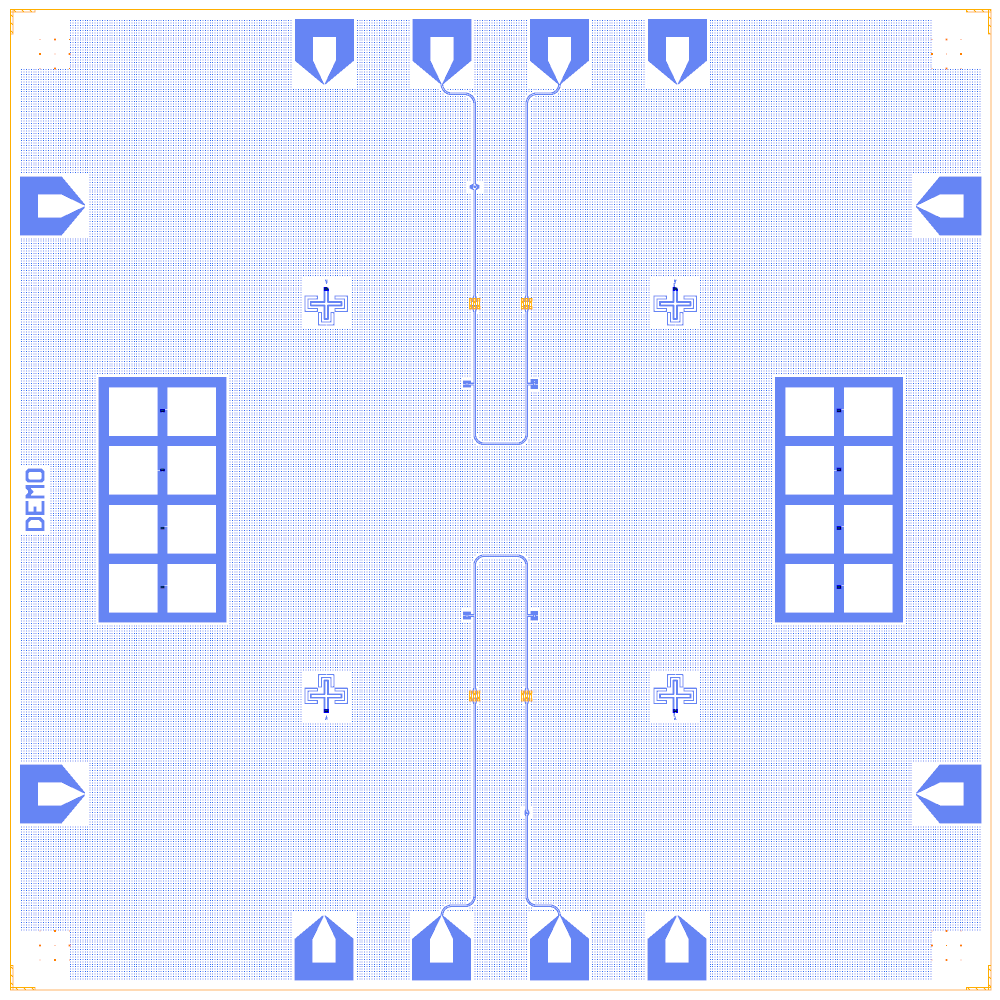

**On the chip so far:** 0 pads · 0 qubits · 16 other components · 8 routes · 0 declared couplings. **This step added** 10 component(s) `RC1`, `PL1`, `RC2`, `PL2`, `RC3`, `PL3`, `RC4`, `PL4` … (+2) and 8 route(s) `PL-1-1`, `PL-1-2`, `PL-1-3`, `PL-1-4`, `PL-2-1`, `PL-2-2`, `PL-2-3`, `PL-2-4`.

WindowsPath('build/snapshots/demo/s4_probe_lines.png')

In [9]:
RR_PATH = {}                                     # readout waypoints, used by the readouts (Design 5)
with d.batch():
    for i, mirrored, fingers in ((1, False, 4), (2, True, 8), (3, False, 5), (4, True, 7)):
        s = -1 if mirrored else 1
        p2 = shift_away(xy(f"QB{i}.cplr1"), base[f"QB{i}"][:2], 600)   # 600 µm out of coupler 1
        p3 = (p2[0] + 300 * s, p2[1])                                    # 300 µm sideways
        cap = add_aligned(d, f"RC{i}", "FingerCapacitorSquare", "a", (p3[0] + 1100 * s, p3[1]),
                          rot=180 if mirrored else 0, finger_number=fingers)
        d.add(f"PL{i}", "WaveguideCoplanarSplitter", snap="bottom", to=cap.b, lengths=[11, 11, 41],
              port_names=["right", "left", "bottom"])
        RR_PATH[i] = [p2, p3]
    for pl, qa, mirrored, fingers in (("PL-1", 1, False, 6), ("PL-2", 4, True, 3)):
        lx, ly = xy(f"PL{qa}.left")
        d.add(f"{pl}-C", "FingerCapacitorTaper", at=(lx, ly + (-2000 if mirrored else 2000)),
              rot=90 if mirrored else 270, finger_number=fingers, taper_length=20)
with d.batch():
    for pl, qa, qbn in (("PL-1", 1, 2), ("PL-2", 4, 3)):
        lx, _ = xy(f"PL{qa}.left")
        c_in = corner(L[f"{pl}-IN"])
        d.route(f"{pl}-1", L[f"{pl}-IN"], f"{pl}-C.a", nodes=[c_in, (lx, c_in[1])])
        d.route(f"{pl}-2", f"{pl}-C.b", f"PL{qa}.left", nodes=[d.waypoint((lx, base[f"QB{qa}"][1]), airbridge=True)])
        d.route(f"{pl}-3", f"PL{qa}.right", f"PL{qbn}.left",
                nodes=[corner(f"PL{qa}.right", 600), corner(f"PL{qbn}.left", 600)])
        rx, _ = xy(f"PL{qbn}.right")
        c_out = corner(L[f"{pl}-OUT"])
        d.route(f"{pl}-4", L[f"{pl}-OUT"], f"PL{qbn}.right",
                nodes=[c_out, (rx, c_out[1]), d.waypoint((rx, base[f"QB{qbn}"][1]), airbridge=True)])
layout_step(d, STEPS / "s4_probe_lines.png", **CHIP)

## Design 5 · Readout: the four λ/2 resonators

**Readout resonators.** From coupler 1 along KQC's path (600 µm out, 300 µm sideways) and then a meander over the
1100 µm segment to the capacitor, with total lengths 5000, 5100, 5200, 5300 µm (λ/2 between two capacitors). The router puts each readout's leftover length into one KQC `Meander` on that 1100 µm segment.

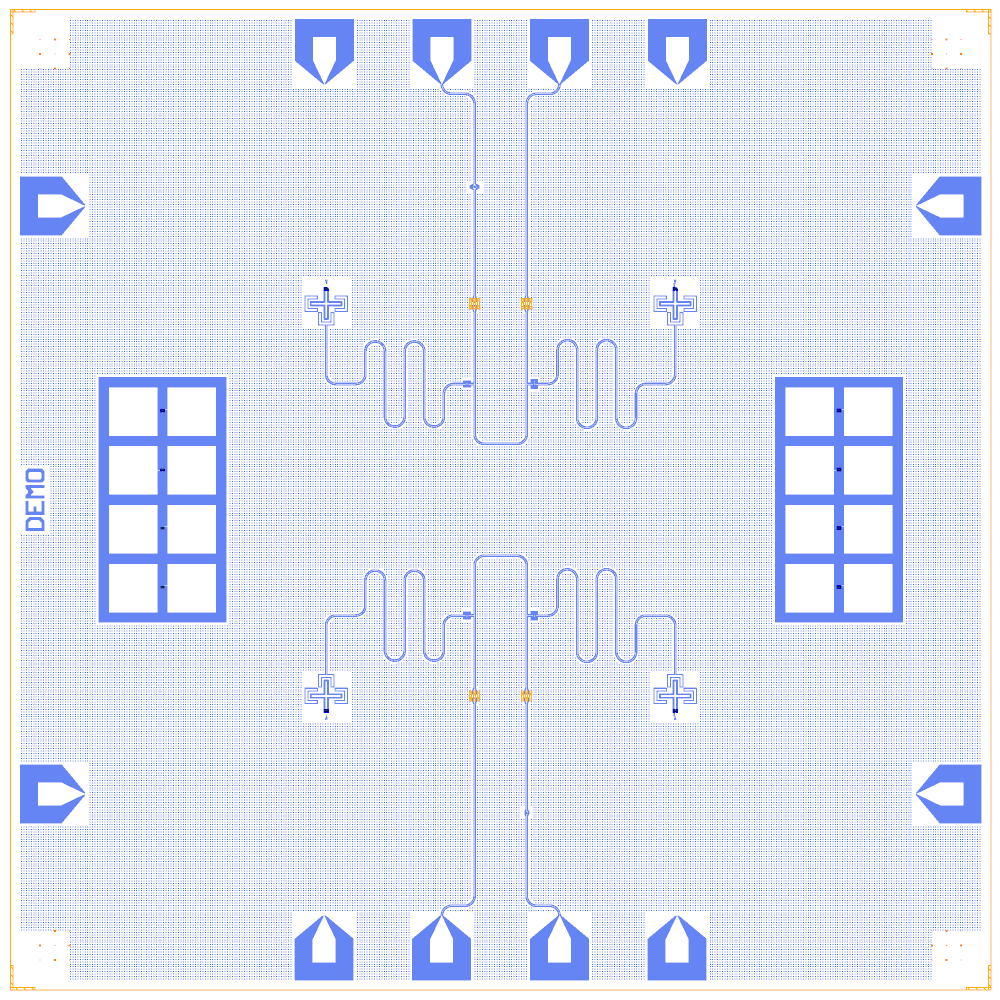

**On the chip so far:** 0 pads · 0 qubits · 16 other components · 12 routes · 0 declared couplings. **This step added** 4 route(s) `RR1`, `RR2`, `RR3`, `RR4`.

WindowsPath('build/snapshots/demo/s5_readouts.png')

In [10]:
lengths = {1: 5000, 2: 5100, 3: 5200, 4: 5300}
with d.batch():
    for i in range(1, 5):
        d.route(f"RR{i}", qb[f"QB{i}"].cplr1, f"RC{i}.a", nodes=RR_PATH[i], meander=lengths[i])
layout_step(d, STEPS / "s5_readouts.png", **CHIP)

## Design 6 · Coupling: the ring of four couplers

**Ring couplers** (a = 4, b = 9 µm) between the qubits' side couplers, 400 µm straight out of each qubit. Each joins two side couplers into one
conductor, so neighbouring qubits couple through it (the LOM's ring, LOM 1).

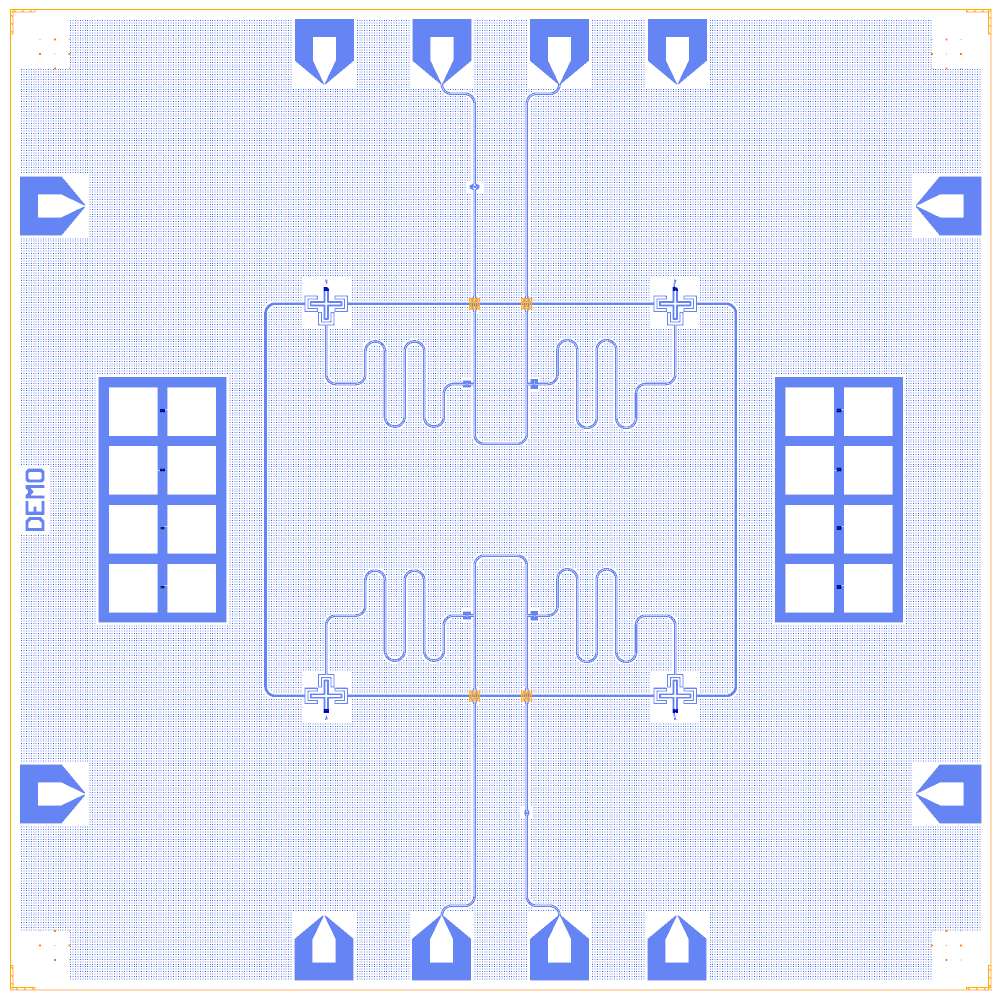

**On the chip so far:** 0 pads · 0 qubits · 16 other components · 16 routes · 0 declared couplings. **This step added** 4 route(s) `CP12`, `CP24`, `CP43`, `CP31`.

WindowsPath('build/snapshots/demo/s6_ring.png')

In [11]:
with d.batch():
    for a, b, k in ((1, 2, 2), (2, 4, 0), (4, 3, 2), (3, 1, 0)):
        pa, pb = f"QB{a}.cplr{k}", f"QB{b}.cplr{k}"
        d.route(f"CP{a}{b}", pa, pb, a=4, b=9, nodes=[shift_away(xy(pa), base[f"QB{a}"][:2], 400),
                                                     shift_away(xy(pb), base[f"QB{b}"][:2], 400)])
layout_step(d, STEPS / "s6_ring.png", **CHIP)

## Design 7 · Routing: the charge and flux lines

**Charge lines** (6 µm open end at the qubit's drive port) and **flux lines**, straight from the launcher corner as
in KQC: every waypoint is derived from a launcher port (`corner(L[...])`), so the pad rule's 79 µm shift of the
launchers carries through (with KQC's hard-coded coordinates the first waypoint would sit 21 µm from the
moved launcher port, shorter than one bend radius, and the route would fail).

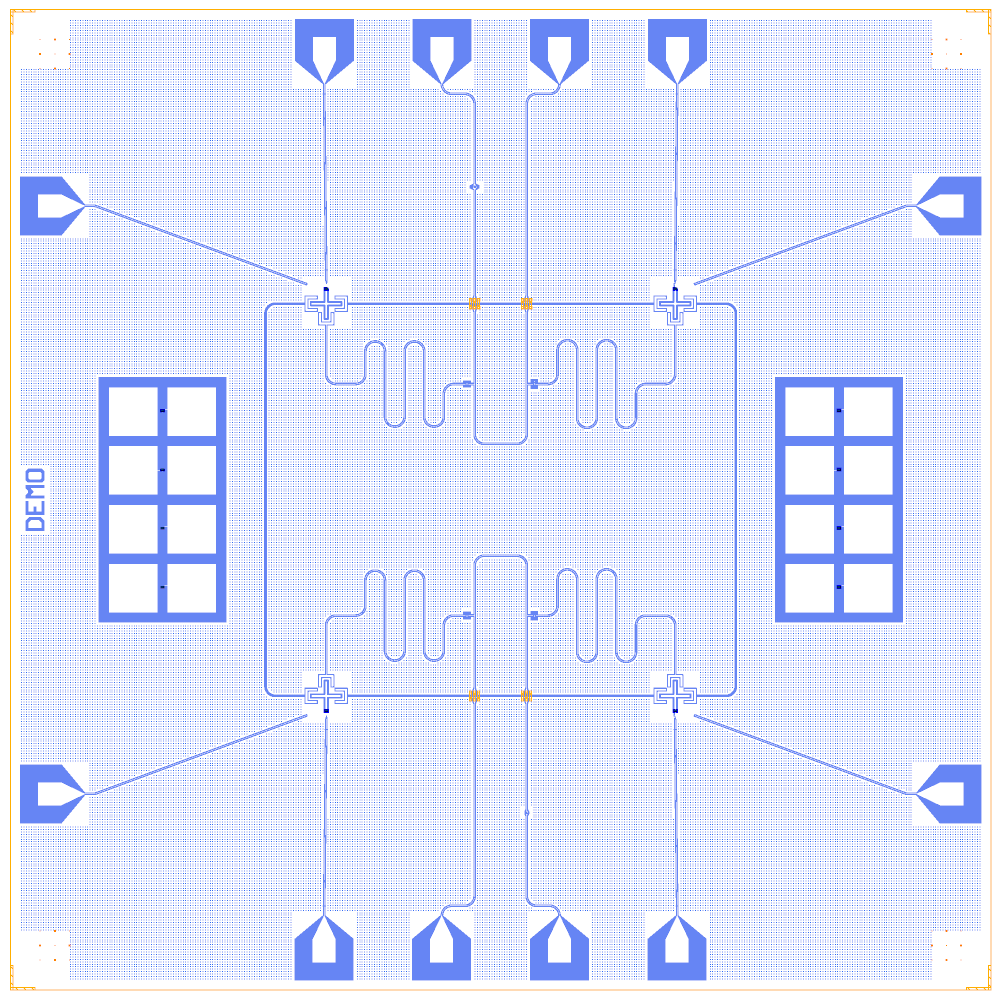

**On the chip so far:** 0 pads · 0 qubits · 16 other components · 24 routes · 0 declared couplings. **This step added** 8 route(s) `DL1`, `FLX1`, `DL2`, `FLX2`, `DL3`, `FLX3`, `DL4`, `FLX4`.

WindowsPath('build/snapshots/demo/s7_control.png')

In [12]:
with d.batch():
    for i in range(1, 5):
        d.route(f"DL{i}", L[f"DL-QB{i}"], qb[f"QB{i}"].drive, nodes=[corner(L[f"DL-QB{i}"])], term2=6)
        d.route(f"FLX{i}", L[f"FL-QB{i}"], qb[f"QB{i}"].flux, nodes=[corner(L[f"FL-QB{i}"]), corner(f"QB{i}.flux")])
layout_step(d, STEPS / "s7_control.png", **CHIP)

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups and centring.** A sim group names a FEM sub-problem: each qubit with its readout and capacitor (Q3D
C-matrix, 300 µm margin) and the four-qubit ring. `center_in_die` checks that the content sits centred in the
die (PDK placement rule) and shifts it if it is more than 50 µm off — here it is centred, so nothing moves. Then
the design is saved: `demo.json` is what DRC, LOM, FEM and `qcc` read. `save_design` compares it with the file it
replaces (the previous run's): the segments above changed how the chip is built (the routes in another order), not
the chip, so it should say *same design*; the file keeps the previous key order.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/kqc/demo.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer demo: 16 instances, 24 routes, live=False> → examples\designs\kqc\demo.json
{'RR1': 5000.0, 'RR2': 5100.0, 'RR3': 5200.0, 'RR4': 5300.0}


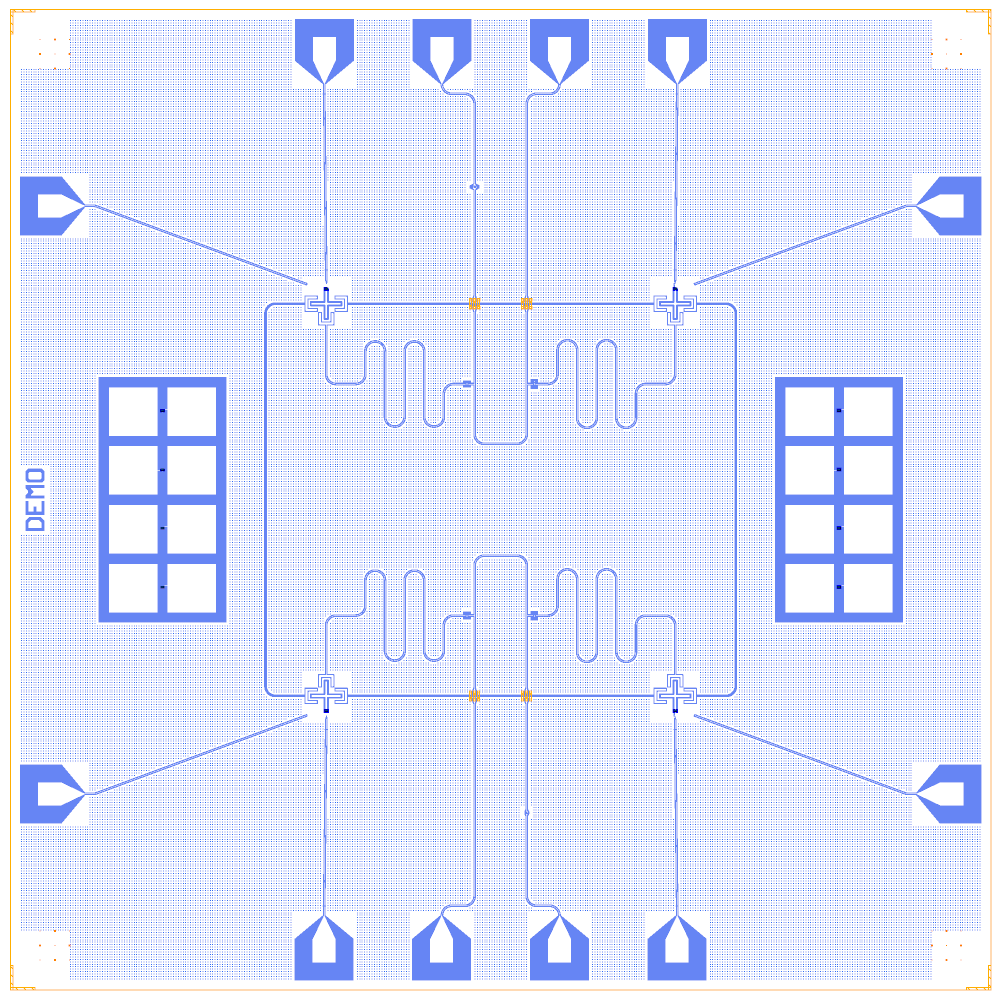

**On the chip so far:** 0 pads · 0 qubits · 16 other components · 24 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/demo/4_routes.png')

In [13]:
for i in range(1, 5):
    d.sim_group(f"QB{i}_RR{i}", [f"QB{i}", f"RR{i}", f"RC{i}"], margin_um=300, analyses=["q3d_cmatrix"])
d.sim_group("ring", ["QB1", "QB2", "QB3", "QB4", "CP12", "CP24", "CP43", "CP31"], analyses=["q3d_cmatrix"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "demo.json")
display(Markdown(same))
print(d, "→", DESIGN)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if k.startswith("RR")})
layout_step(d, STEPS / "4_routes.png", **CHIP)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices.

`pdk_rn` judges the device R_n: for a SQUID that is the two junctions in parallel (what a probe station measures
across it), 45 kΩ here — inside the 40–50 kΩ window, so the SQUIDs are not flagged. The v1 run: DRC clean, no warnings.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit nodes,
routes join nodes (or become transmission-line resonators), launchers are 50 Ω ports or drive / flux controls.

For the Swissmon: an island node with C to ground and the SQUID to ground, one coupler node per side coupler
(C_g to the island, C to ground). A ring coupler joins two coupler nodes into one conductor; a readout route
between two capacitors with a meander becomes a λ/2 `TLres`; charge and flux lines are drive / flux controls on
the SQUIDs. The first table lists the nodes and the FEM nets that form each one; the second the branches with
their component estimates.

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**QB1's ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith("QB1."))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

QuCat finds the normal modes of the circuit (frequencies, κ into the 50 Ω ports, anharmonicities) and QuTiP
diagonalises the dressed Hamiltonian of the first modes (f_q, α, f_r, χ). Each qubit is simulated with its
readout, capacitor and its whole probe line (input capacitor, both T's, all four legs); then the ring as one
circuit and each coupled pair with its ring coupler.

Expected with the PDK SQUIDs (from the v1 run): f_q ≈ 5.8 GHz (KQC's assumed 16 nH gave ≈ 3.9 GHz), α ≈ −200 MHz, λ/2 readouts
≈ 10.7–11.4 GHz. The four qubits are identical, so the ring's normal modes hybridise (a per-pair ZZ is not
defined; the ZZ table says so) and the pairwise runs give g from the splitting of the two normal modes.

In [ ]:
groups = {}
for i, (pl, other) in ((1, ("PL-1", 2)), (2, ("PL-1", 1)), (3, ("PL-2", 4)), (4, ("PL-2", 3))):
    # the qubit, its readout and capacitor, and the whole probe line: input capacitor, both T's, all four legs
    groups[f"QB{i}+RR{i}"] = [f"QB{i}", f"RR{i}", f"RC{i}", f"PL{i}", f"PL{other}", f"{pl}-C"] + [f"{pl}-{k}" for k in (1, 2, 3, 4)]
results = simulate_groups(d, groups)
display(Markdown(groups_md(results)))

In [ ]:
ring = simulate_groups(d, {"ring": ["QB1", "QB2", "QB3", "QB4", "CP12", "CP24", "CP43", "CP31"]}, max_modes=4,
                       excitations=[3, 3, 3, 3])
display(Markdown("**Four-qubit ring, QuCat normal modes:**\n\n" + modes_md(ring["ring"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(ring)))
pairs = {f"QB{a}+QB{b}": [f"QB{a}", f"QB{b}", f"CP{a}{b}"] for a, b in ((1, 2), (2, 4), (4, 3), (3, 1))}
coupled = simulate_groups(d, pairs)
rows = [f"| {g} | {r.modes[0].f_GHz:.4f} | {r.modes[1].f_GHz:.4f} | {abs(r.modes[1].f_GHz - r.modes[0].f_GHz) * 500:.2f} |"
        for g, r in coupled.items()]
display(Markdown("**Ring couplers, one qubit pair at a time** (identical qubits: the normal modes split by 2g)\n\n"
                 "| pair | f₋ (GHz) | f₊ (GHz) | g = Δf/2 (MHz) |\n|---|---|---|---|\n" + "\n".join(rows)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares the
readouts; filled markers are the QuTiP dressed values) and the four-qubit ring, (b) the dispersive shift |χ| of each
readout. The λ/2 readouts sit ≈ 5 GHz above the qubits (from the v1 run), so χ is small.

In [ ]:
plot_lom({**results, **ring}, STEPS / "lom.png", title="demo: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. A design change is a parameter change in the design, followed by a rebuild and a new LOM run. Here: shorten
readout RR1 from 5000 to 4600 µm. A shorter λ/2 line raises f_r (≈ +0.9 GHz), which increases the qubit–readout
detuning, so |χ| drops. The change is made on a copy (`design_copy`), so `demo.json` keeps the source's length.

In [ ]:
d2 = design_copy(DESIGN)
d2["RR1"].set(meander=4600)
after = simulate_groups(d2, {"QB1+RR1": groups["QB1+RR1"]})
display(Markdown("**RR1: 5000 → 4600 µm**\n\n" + params_delta_md({"QB1+RR1": results["QB1+RR1"]}, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/kqc/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

One Q3D C-matrix job per sim group: the group is cut out of the chip with its margin, every line leaving the box
ends in a port, the junction is a lumped port, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and the C-matrix nets (named after the islands, couplers and routes,
so the result maps back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

The sim groups ask for Q3D only; `QB1_RR1` is also exported in eigenmode (Simulate 3): `build_simulation` exports any
analysis for a sim group, so the design file stays as it is.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/kqc/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group (their own analysis)
jobs_eig = export_sims(DESIGN, ["QB1_RR1"], analysis="eigenmode_epr")   # the same group in eigenmode (Simulate 3)
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

Per qubit group: the island, coupler 1 with its readout capacitor and the lines the box cuts (ring couplers, charge
line, probe-line legs) as named nets; `ring`: the four islands and the eight side couplers. Each net is named after
its LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`,
else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `QB1_RR1` box (the qubit, its readout and capacitor, 300 µm margin) in HFSS eigenmode: the SQUID is a lumped
L_J ‖ C_J sheet, the lines the box cuts (both probe-line legs, the ring couplers, the charge and flux lines) end in
50 Ω, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the
junction's participation into dressed frequencies, α and χ. The box was sized for Q3D: check the export notes for a
line cut on a bend.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives S21 along probe line 1 through the same box, where RR1 (coupled through RC1 and the T) shows
up as a notch. The library cannot hand the solved eigenmode **mesh** itself to a driven setup (no such option yet), so
`driven_from_eigenmode` does the nearest honest thing: the same sim group and box, the eigenmode job's mesh seeds, the
adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r, ≈ 11.4 GHz in the v1 run, before the
eigenmode is solved) and a fast sweep around it.

In [ ]:
f_drv = results["QB1+RR1"].params.get("RR1.f_GHz")   # the LOM's RR1 frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "QB1_RR1", jobs_eig["QB1_RR1"][0], keep_eig["QB1_RR1"], f_guess=f_drv)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["QB1_RR1"]:
    display(Markdown(driven_md(keep_drv["QB1_RR1"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: a qubit; ≈ 0: a resonator), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {"QB1": results["QB1+RR1"].params.get("QB1.f_q_GHz"), "RR1": f_drv}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: QB1's mode is the one its SQUID participates in most, RR1's the remaining mode
nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms, κ = f/Q of the
50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds RR1's notch.

In [ ]:
fem_values = {}
if keep_eig["QB1_RR1"]:
    fem_values = epr_values(keep_eig["QB1_RR1"], {"QB1": "RR1"}, {"RR1": f_drv})
if keep_drv["QB1_RR1"]:
    fem_values.update({f"driven {k}": x for k, x in driven_values(keep_drv["QB1_RR1"], "RR1", f_drv).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {x:.5g} |" for k, x in fem_values.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ of QB1 / RR1 from "
          "pyEPR, and RR1's S21 notch.")

## Results 3 · FEM against the LOM

Two comparisons. **LOM on the Q3D C-matrix:** per qubit, `fill` replaces the capacitance estimates of its group by
the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM runs again.
**FEM directly:** QB1's eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component estimates
(LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for i in range(1, 5):
    g, est = f"QB{i}+RR{i}", results[f"QB{i}+RR{i}"].params
    keys = [f"QB{i}.f_q_GHz", f"QB{i}.alpha_MHz", f"RR{i}.f_GHz", f"RR{i}.chi_MHz", f"RR{i}.kappa_MHz"]
    if keep_q3d.get(f"QB{i}_RR{i}"):
        on_fem = simulate(fill(d.lom(select=groups[g]).model, DESIGN, keep_q3d[f"QB{i}_RR{i}"]), max_modes=2).params
        rows += [(key, est.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys]
    rows += [(key, est.get(key), fem_values[key], "eigenmode + pyEPR") for key in keys if key in fem_values]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to QB1's eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

KQC's `Demo` states no frequencies, so this notebook sets one as an exercise: **QB1 at 6.0 GHz**, ≈ 0.19 GHz above
where the LOM puts it (from the v1 run: 5.810 GHz). The four qubits are identical, so the ring's modes hybridise
(LOM 1); a QB1 detuned by ≈ 0.19 GHz, far more than the ring coupling (g ≈ 2.8 MHz in the v1 run), separates it from
its ring neighbours QB2 and QB3. It is reachable inside the PDK junction window: L_J goes from 6.73 nH to ≈ 6.33 nH,
R_n ≈ 42 kΩ (`pdk_lj_bounds` keeps the feedback within 40–50 kΩ). The readouts are not targeted.

The targets go on a copy (`target_copy` → `build/demo_target.json`), so the design file keeps its own (none).
`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — on the Q3D values where a solve was kept — and picks one value per quantity (the consensus).
`loop.feedback` anchors a surrogate on that point and proposes the knobs that put the target inside its tolerance
(f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The revision changes the LOM's
L_J; the drawn SQUID keeps its 0.25 µm straight fingers until it is sized again with
`trilayer_junction(..., lj_nH=..., squid=True)`. If the consensus table is empty, `loop.analyse` found no
qubit–readout pair it can tune here (see the log's requests): the cell then says so instead of proposing knobs.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"QB1": {"f_q_GHz": 6.0}}   # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
the target is inside its tolerance or `MAX_ITER` revisions are made (`build/demo/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` each revision's QB1_RR1 Q3D job is exported and solved first (`solve_rev`), so the
loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's value against the target
and the knob it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D component jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ('QB1_RR1',)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `demo.json` (saved in Design 8) is the whole design: `qcc build examples/designs/kqc/demo.json`
rebuilds `build/demo.oas` + its sidecar from it, and the KLayout plugin, `qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the 3/0
keep-out (filled: CPW footprint + 10 µm, components' etch bbox + 24 µm, plus every cheese hole, so the PDK cheese holes are on 3/0 too), the trilayer junction fingers 2/0 + 4/0
and spacer 50/0 with the 51–53/0 dose gradient, airbridges 300/301, and the frame (100/0, 1000/0, 1001/0). The
cheese source is `build`: the PDK cheese drawn over the whole die in the build (`cheese: "chip"`, 124 250 holes in a probe) stands, and no PDK band is added.
Corner rounding (fab only) is skipped unless `FULL_FAB`; `qcc mask examples/designs/kqc/demo.json` writes the
complete file with rounding.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`), and the builder notes which crossing
lines are then open. `setup.geometry` says what the export left out; QB1's group shows both settings.

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB1_RR1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Fab 2 · Snapshots

The full chip (the PDK cheese, ≈ 0.12 M holes, gives the ground a light, even texture at this scale), QB1 with its couplers, QB1's trilayer SQUID
at the top arm and its flux line, the QB1 readout capacitor on its probe-line T, the die frame's south-west
corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0), QB1 in the **fab view** (the mask written in
Fab 1: base etch 1/0 with the PDK's 5 µm cheese holes kept clear of the qubit, 3/0 with the keep-out and the same holes,
the trilayer layers),
and — for comparison — KQC's own `Demo` chip built stand-alone (KQC's ChipFrame, Manhattan SQUIDs, no grid).

The zooms and the fab view show the individual cheese holes; the chip boundary 100/0 is drawn as an outline.

In [ ]:
show_snapshot(d, OUT / "demo.png", box=(-100, -100, 10100, 10100))
qx, qy = base["QB1"][:2]
show_snapshot(d, OUT / "demo_qb1.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), width=420)
show_snapshot(d, OUT / "demo_squid.png", box=(qx - 60, qy + 100, qx + 60, qy + 220), width=360)   # SQUID at the top arm tip
cx, cy = port_xy(d, "RC1.b")
show_snapshot(d, OUT / "demo_coupler.png", box=(cx - 200, cy - 200, cx + 200, cy + 200), width=360)
show_snapshot(d, OUT / "demo_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "demo_fab.oas", OUT / "demo_fab_qb1.png", box=(qx - 250, qy - 250, qx + 250, qy + 250),
          size=(1200, 1200), width=420);   # fab view: 1/0 with the grid holes, 3/0, junction layers

In [ ]:
from kqcircuits.chips.demo import Demo
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_demo")
top.insert(pya.DCellInstArray(Demo.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "demo_kqc_original.oas"))
snap_file(Path("build") / "demo_kqc_original.oas", OUT / "demo_kqc.png", box=(-100, -100, 10100, 10100), width=420);

## Summary

| | |
|---|---|
| **matches the source** | every KQC element with its parameters, positions and orientations; the ARD24 launcher assignment; every route's path; readout lengths 5000–5300 µm; the sim groups; the whole-area cheese coverage (with the PDK squares instead of KQC's grid) |
| **differs (PDK)** | Quantcore die frame instead of KQC's ChipFrame; launchers 79 µm further in (outer etch 100 µm from the edge, `frame.pad_edge`); sapphire instead of silicon; Quantcore trilayer SQUIDs (f_q ≈ 5.8 GHz instead of ≈ 3.9 GHz); waypoints derived from the launcher ports |
| **simplified** | router-fitted readout meanders; no extra `n_bridges` airbridges |
| **PDK design warnings** | as listed in Check 1 (the SQUIDs' device R_n, 45 kΩ, is inside the window) |
| **FEM** | 5 Q3D jobs, QB1's eigenmode and driven jobs exported (`build/jobs/demo_*`), not solved here |
| layout | built in eight segments (die and launchers, the launcher check, the qubits — before the readout line, whose parts are placed from their ports —, the probe lines, the readouts, the ring, the charge and flux lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (QB1 6.0 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells; the revision's drawn SQUID keeps its fingers (size it with `trilayer_junction`) |